1. Business scenario

In [7]:
# Imagine we work for a subscription- based comapany
# Customers subscribe to a service and pay monthliy charges
# Some customers continue their sunscriptions, while other cancel
# The company wants to uderstand customer churn.
# Churn means customers discontinue their service during a defined reporting period
# The bussiness wants to these questions :
# What percentage of customers leave?
# Which customer group have the highest churn?
# Does customer tenure influence churn?
# Does monthly spending differ between churned and retained customers?
# Which factors may be associated with customer churn?




In [8]:
# 2. Tools and Technologies
# 1.Python
# 2.Pandas
# 3.NumPy
# 4.Matplotlib
# 5.Seaborn
# 6.Scilkit-learn(optional predictive extension)
# 7.Jupiter Notebook | Google colab

In [9]:
# from types import MethodDescriptorType
# from ast import Subscript
# # 3. dataset requirments
# Column            Description
# customer_id       Customer identifier
# tenure_months     Months as a customer
# cotract_type      Monthly, annual, atc
# monthly_charges   Monthly Subscription cost
# payment_method    Payment Method
# support_calls     Number of support interactions
# usage_level       Service usage category
# churn             Whether the customer Left

# for the main analysis, define churn consistency as a customer whose Subscription ended during the reporting period.



In [10]:
# how to install libraries
!pip install Pandas NumPy Matplotlib Seaborn

In [31]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
# Upload csv files
from google.colab import  files
uploaded = files.upload()

Saving customer_churn_large_10000.csv to customer_churn_large_10000 (1).csv


In [19]:
import pandas as pd
df = pd.read_csv("customer_churn_large_10000.csv")

In [20]:
# inspect the dataset
# display first fivr rows
df.head()

# desplay last five rows
df.tail()

# check the number of rows and columns
df.shape

# check the coulumn name
df.columns

# check the data type and missing values
df.info()

# check the statistical summary
df.describe()

# check the missing values
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      10000 non-null  object 
 1   tenure_months    10000 non-null  int64  
 2   contract_type    10000 non-null  object 
 3   monthly_charges  10000 non-null  float64
 4   payment_method   10000 non-null  object 
 5   support_calls    10000 non-null  int64  
 6   usage_level      10000 non-null  object 
 7   churn            10000 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 625.1+ KB


,0
customer_id,0
tenure_months,0
contract_type,0
monthly_charges,0
payment_method,0
support_calls,0
usage_level,0
churn,0


In [21]:
from pandas.core.arrays import numeric
# Clean the data
# Rmove dupicate customer records
df = df.drop_duplicates(
    subset = ["customer_id"],
)

# Convert numeric columns
numeric_columns =[
    "tenure_months",
    "monthly_charges",
    "support_calls"
    ]
for col in numeric_columns:
  df[col] =pd.to_numeric(
      df[col],
      errors="coerce"
  )
print(numeric_columns)

['tenure_months', 'monthly_charges', 'support_calls']


In [22]:
# inspect missing values
print(df.isnull().sum())

customer_id        0
tenure_months      0
contract_type      0
monthly_charges    0
payment_method     0
support_calls      0
usage_level        0
churn              0
dtype: int64


In [23]:
# Check the invalid tenure
invalid_tenure = df[
    df["tenure_months"]<0
]
print(invalid_tenure)

Empty DataFrame
Columns: [customer_id, tenure_months, contract_type, monthly_charges, payment_method, support_calls, usage_level, churn]
Index: []


In [25]:
# Understand the churn distrubution
print(
    df["churn"].value_counts()
)

# calculate churn percentage
churn_rate = (
    df["churn"].eq("Yes").mean() *100
)
print("Churn Rate:",round(churn_rate,2),"%")

churn
No     8158
Yes    1842
Name: count, dtype: int64
Churn Rate: 18.42 %


In [26]:
#OR
total_customers = len(df)
churn_customers = (df["churn"]== "Yes").sum()
churn_percentage =(churn_customers /total_customers)*100
print("churn Percentage:",round(churn_percentage,2),"%")

churn Percentage: 18.42 %


In [27]:
# Anlyse churned by contract type
contract_churn = pd.crosstab(
    df["contract_type"],
    df["churn"],
    normalize="index"
)*100
print(contract_churn)

# explian pd.crosstab as tool for comparing categorical variable
# normalize="index":calculate percentage within each contract category

churn                 No        Yes
contract_type                      
Annual         84.275677  15.724323
Monthly        78.168886  21.831114
Two Year       88.547120  11.452880


In [28]:

# Analyse churn by customer tenure
df["tenure_group"] = pd.cut(
    df["tenure_months"],
    bins=[0,6,12,24,48,np.inf],
    labels =[
        "0-6 Months",
        "7-12 Months",
        "13-24 Months",
        "25-48 Months",
        "48+ Months"
    ],
    include_lowest=True
)
# claculate churn by tenure group
tenure_churn =df.groupby(
    "tenure_group",
    observed=False
    )["churn"].apply(lambda x: x.eq("Yes").mean()*100)

print(tenure_churn)
# Explain cut(): as a way to convert continous values into meaningful groups

tenure_group
0-6 Months      34.276387
7-12 Months     31.490385
13-24 Months    25.779871
25-48 Months    16.939216
48+ Months       8.401330
Name: churn, dtype: float64


In [29]:
# Analyse monthly charges
charge_Analysis=(
df.groupby("churn")["monthly_charges"]
     .agg(["mean","median","min","max"])
)
print(charge_Analysis)

             mean   median    min     max
churn                                    
No      81.400071   79.445  20.01  149.99
Yes    102.354142  108.410  20.03  149.85


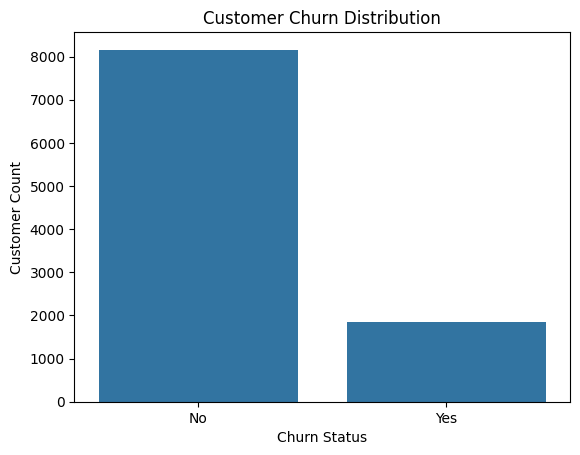

In [36]:
# Create visvlisation
#Churn distribution:
sns.countplot(
    data=df,
    x="churn",

)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Customer Count")
plt.show()

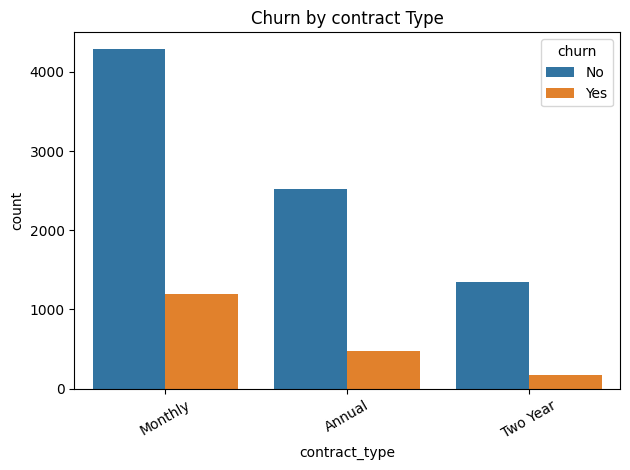

In [38]:
# Churn by cotract
sns.countplot(
    data=df,
    x="contract_type",
    hue="churn"
)
plt.title("Churn by contract Type")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



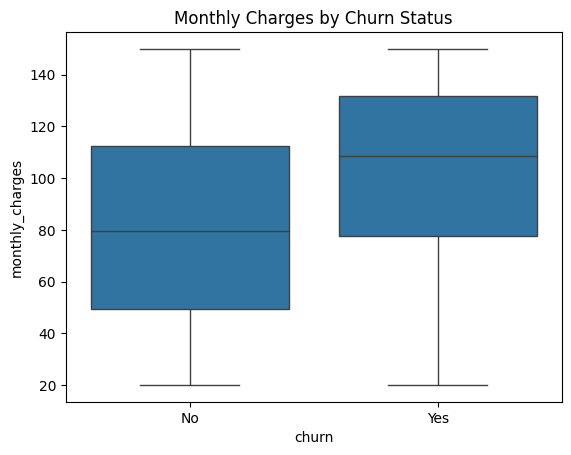

In [41]:
# Monthly charges
sns.boxplot(
    data=df,
    x="churn",
    y="monthly_charges"
)
plt.title("Monthly Charges by Churn Status")
plt.show()

In [42]:
# Optional extension
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import  LogisticRegression
from sklearn.metrics import classification_report

In [57]:
# prepare feature
features =[
    "tenure_months",
    "monthly_charges",
    "support_calls",
    "payment_method",
    "contract_type",
    "usage_level"
]
x = df[features]
y = df["churn"].map({
    "No":0,
    "Yes":1
})
#Suparate numerical and categorocal columns
numeric_features =[
    "tenure_months",
    "monthly_charges",
    "support_calls"
]
categorical_features =[
    "payment_method",
    "contract_type",
    "usage_level"
]

# Create preprocessing piplines
numeric_pipeline = Pipeline(
    steps=[
       ("imputer",SimpleImputer(strategy="median")),
       ("scaler",StandardScaler())
    ]
)
categorical_pipeline = Pipeline(
    steps = [
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("encoder",OneHotEncoder(handle_unknown="ignore"))

    ]
)
# combine pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num",numeric_pipeline,numeric_features),
        ("cat",categorical_pipeline,categorical_features)
    ]
)
# Create model
model = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",LogisticRegression(max_iter=1000))
    ]
)
# Split the data
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,
    random_state=42,
    stratify=y
)

# Train
model.fit(x_train,y_train)
# predict
prediction = model.predict(x_test)
# Evaluate
print(classification_report(
    y_test,
    prediction
))

              precision    recall  f1-score   support

           0       0.84      0.97      0.90      1632
           1       0.61      0.18      0.28       368

    accuracy                           0.83      2000
   macro avg       0.72      0.58      0.59      2000
weighted avg       0.80      0.83      0.79      2000

